# Linear Regression in Python, Line by Line

**Regression Lab · Lesson 3** · College of Computer Studies, University of Technology Bahrain  
Prepared by **Eng. Saeed Serwan Abdulsattar**

Interactive version with hover-to-explain code: **https://saeedserwan.github.io/regression/code-linear.html**

A complete, runnable notebook that takes a real-style dataset from a CSV file to a trained, evaluated and visualised linear regression model. Every line of code is explained: hover over (or tap) a line to see what it does.

**You will learn to:**

1. Load and inspect a dataset with pandas
2. Visualise distributions and relationships with Matplotlib
3. Split data, train a model and read its coefficients
4. Compute MAE, MSE, RMSE, R², adjusted R² and MAPE
5. Diagnose the model with residual and predicted-vs-actual plots

> Run the cells from top to bottom (Shift + Enter). After each code cell, a **Line by line** note explains what every line does.

## 1. Import the libraries

Every Python data-science project starts by importing the tools it needs. We use four libraries:
**NumPy** for maths, **pandas** for tables, **Matplotlib** for charts and **scikit-learn** for machine learning.

In [1]:
%config InlineBackend.figure_format = "retina"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import r2_score, mean_absolute_percentage_error

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True

**Line by line**

1. `%config InlineBackend.figure_format = "retina"`  
   A Jupyter setting (not Python): draw sharper plots on high-resolution screens.
2. `import numpy as np`  
   NumPy provides fast arrays and maths functions (mean, square root, …). `as np` is the standard nickname.
3. `import pandas as pd`  
   pandas reads the CSV file into a DataFrame: a table with named columns, like a spreadsheet.
4. `import matplotlib.pyplot as plt`  
   Matplotlib's plotting interface. Every chart in this notebook is drawn with `plt`.
5. `from sklearn.model_selection import train_test_split`  
   A helper that randomly splits the data into a training part and a test part.
6. `from sklearn.linear_model import LinearRegression`  
   The linear regression model, fitted by ordinary least squares.
7. `from sklearn.metrics import mean_absolute_error, mean_squared_error` …  
   Ready-made functions for the evaluation metrics.
8. `plt.rcParams["figure.figsize"] = (7, 4.5)`  
   Default figure size (width, height) in inches for every chart we draw.
9. `plt.rcParams["axes.grid"] = True`  
   Add light grid lines to all charts so values are easier to read.

## 2. Load the dataset

The dataset records **25 houses**: their floor area in m² and their price in thousands of Bahraini dinars (BD).
It is stored as a CSV file in the course repository, so pandas can read it straight from the web.

In [2]:
url = "https://raw.githubusercontent.com/SaeedSerwan/regression/main/data/house_size_price.csv"
df = pd.read_csv(url)
df.columns = ["area", "price"]
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (25, 2)


,area,price
0,244,92.2
1,269,105.9
2,106,43.9
3,224,108.5
4,214,89.3


**Line by line**

1. `url = "https://raw.githubusercontent.com/SaeedSerwan/regression/main/data/house_size_price.csv"`  
   The file's web address. You could also download the CSV and use its local file name instead.
2. `df = pd.read_csv(url)`  
   Read the CSV into a DataFrame called `df`. Each row is one house; each column is one variable.
3. `df.columns = ["area", "price"]`  
   Rename the columns to short names that are quicker to type: area (m²) and price (BD thousands).
4. `print("Rows and columns:", df.shape)`  
   `.shape` gives (rows, columns). We expect 25 houses and 2 columns.
5. `df.head()`  
   Show the first 5 rows. In a notebook, the value of the last line of a cell is displayed automatically.

## 3. Explore the data

Before modelling, check the data is clean and get a feel for its scale.

In [3]:
print("Missing values per column:")
print(df.isna().sum())
df.describe().round(1)

Missing values per column:
area     0
price    0
dtype: int64


,area,price
count,25.0,25.0
mean,241.4,102.2
std,80.3,32.1
min,88.0,43.9
25%,207.0,74.3
50%,241.0,105.9
75%,286.0,118.2
max,393.0,171.7


**Line by line**

1. `print("Missing values per column:")`  
   A heading for the next output.
2. `print(df.isna().sum())`  
   `isna()` marks empty cells as True; `.sum()` counts them per column. Both should be 0.
3. `df.describe().round(1)`  
   Summary statistics for each column: count, mean, standard deviation (std), min, quartiles and max.

### Distributions

A **histogram** shows how the values of one variable are spread out.

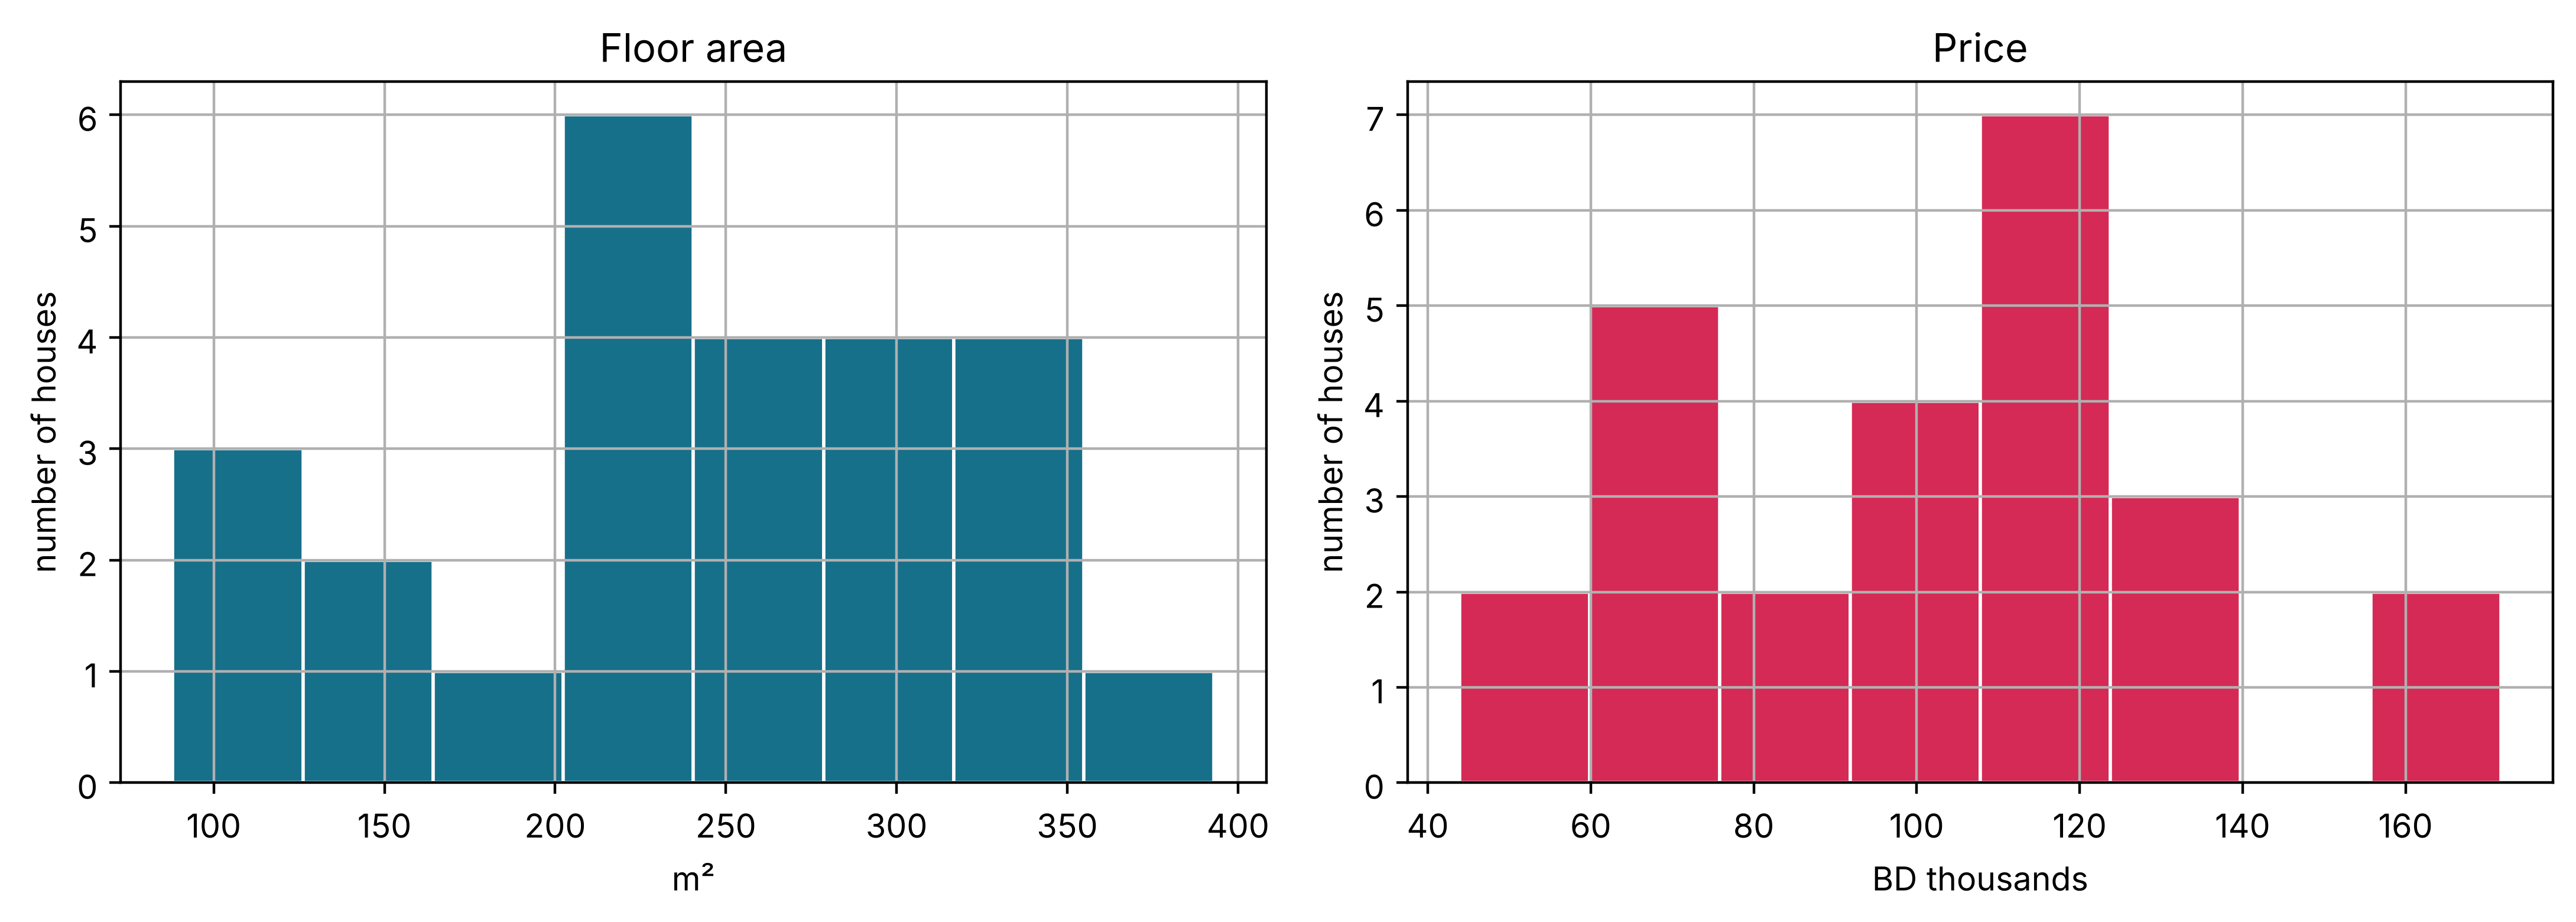

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(df["area"], bins=8, color="#17708a", edgecolor="white")
axes[0].set(title="Floor area", xlabel="m²", ylabel="number of houses")
axes[1].hist(df["price"], bins=8, color="#d52a55", edgecolor="white")
axes[1].set(title="Price", xlabel="BD thousands", ylabel="number of houses")
plt.tight_layout()
plt.show()

**Line by line**

1. `fig, axes = plt.subplots(1, 2, figsize=(11, 4))`  
   One figure with two side-by-side panels (1 row, 2 columns). `axes[0]` is the left panel, `axes[1]` the right.
2. `axes[0].hist(df["area"], bins=8, color="#17708a", edgecolor="white")`  
   Left panel: a histogram of floor area, grouped into 8 bins (bars).
3. `axes[0].set(title="Floor area", xlabel="m²", ylabel="number of houses")`  
   Give the panel a title and axis labels.
4. `axes[1].hist(df["price"], bins=8, color="#d52a55", edgecolor="white")` …  
   Right panel: the same for price.
5. `plt.tight_layout()`  
   Adjust the spacing so titles and labels don't overlap.
6. `plt.show()`  
   Display the figure.

### The relationship

A **scatter plot** places one dot per house, with the feature on the x-axis and the target on the y-axis.
If the dots follow a straight-line trend, linear regression is a sensible model.

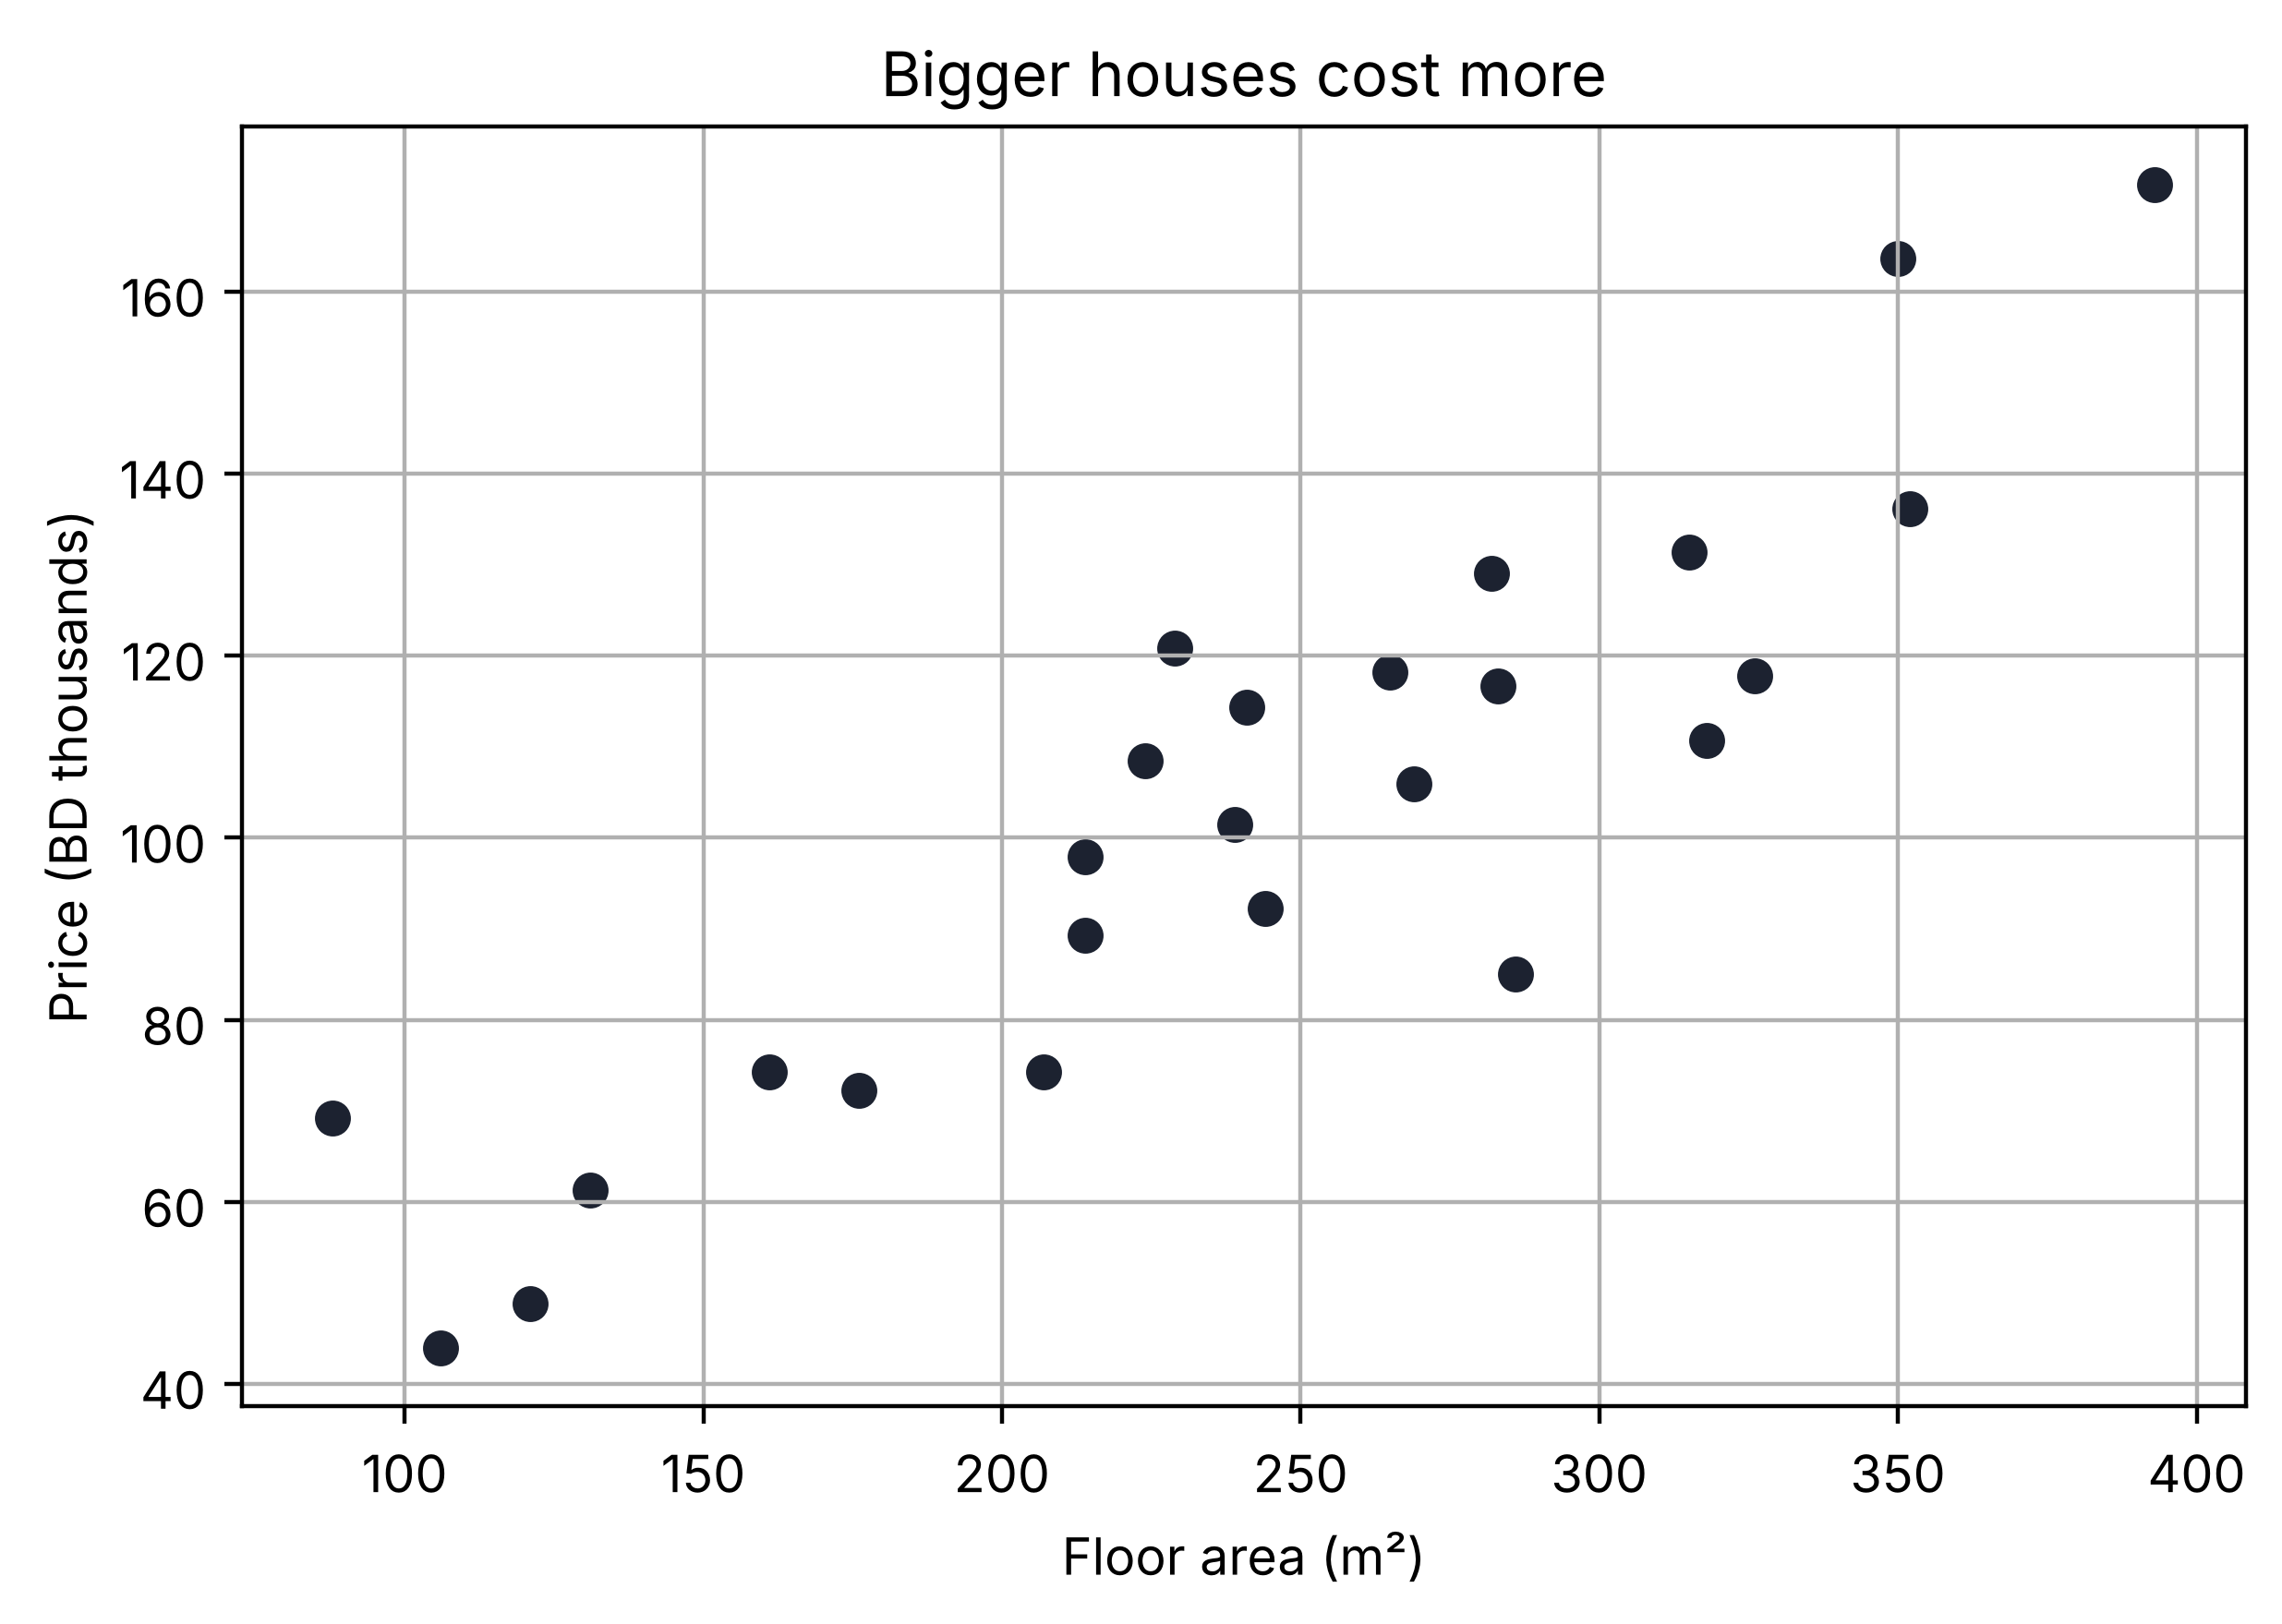

Correlation r = 0.901


In [5]:
plt.scatter(df["area"], df["price"], color="#1c2230")
plt.xlabel("Floor area (m²)")
plt.ylabel("Price (BD thousands)")
plt.title("Bigger houses cost more")
plt.show()

r = df["area"].corr(df["price"])
print(f"Correlation r = {r:.3f}")

**Line by line**

1. `plt.scatter(df["area"], df["price"], color="#1c2230")`  
   One dot per house: area across, price up.
2. `plt.xlabel("Floor area (m²)")` …  
   Always label your axes, with units.
3. `plt.title("Bigger houses cost more")`  
   A good title states the takeaway, not just the variable names.
4. `plt.show()`  
   Display the chart.
5. `r = df["area"].corr(df["price"])`  
   Pearson correlation r: how tightly the points follow a straight line, from −1 to +1.
6. `print(f"Correlation r = {r:.3f}")`  
   An f-string inserts the value of `r`; `:.3f` rounds it to 3 decimal places.

A correlation close to **+1** confirms a strong, positive, linear relationship.

## 4. Prepare the data

scikit-learn expects the inputs (**features**, `X`) and the output (**target**, `y`) separately.
We also hold back some houses as a **test set**: the model never sees them during training, so they tell us how well it works on new data.

In [6]:
X = df[["area"]]
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print(f"Training houses: {len(X_train)}  ·  test houses: {len(X_test)}")

Training houses: 20  ·  test houses: 5


**Line by line**

1. `X = df[["area"]]`  
   Features. Double brackets return a 2-D table; scikit-learn requires 2-D input even when there is only one feature.
2. `y = df["price"]`  
   Target. Single brackets return a 1-D column (a pandas Series).
3. `X_train, X_test, y_train, y_test = train_test_split(`  
   Shuffle the rows and split them into training and test sets.
4. `X, y, test_size=0.2, random_state=42)`  
   `test_size=0.2` keeps 20 % of houses for testing. `random_state` fixes the shuffle so everyone gets the same split.
5. `print(f"Training houses: {len(X_train)}  ·  test houses: {len(X_test)}")`  
   Check the sizes: 20 for training, 5 for testing.

## 5. Train the model

Training finds the slope $m$ and intercept $b$ of the line $\hat{y} = m\,x + b$ that make the squared errors on the training data as small as possible.

In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

m = model.coef_[0]
b = model.intercept_
print(f"price = {m:.4f} × area + {b:.2f}")

price = 0.3180 × area + 23.34


**Line by line**

1. `model = LinearRegression()`  
   Create an untrained linear regression model.
2. `model.fit(X_train, y_train)`  
   Train it: least squares chooses the slope and intercept that minimise the squared errors on the training data.
3. `m = model.coef_[0]`  
   The learned slope. `coef_` holds one value per feature; we take the first (and only) one.
4. `b = model.intercept_`  
   The learned intercept.
5. `print(f"price = {m:.4f} × area + {b:.2f}")`  
   Print the fitted equation.

**Reading the result:** the slope says each extra square metre adds about that many *thousand* BD to the price.
The intercept is the predicted price of a 0 m² house. It is needed to position the line, but it has no practical meaning here.

## 6. Make predictions

In [8]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "area": X_test["area"],
    "actual": y_test,
    "predicted": y_pred.round(1),
})
results["error"] = (results["actual"] - results["predicted"]).round(1)
results

,area,actual,predicted,error
8,214,97.9,91.4,6.5
16,239,101.5,99.3,2.2
0,244,92.2,100.9,-8.7
23,350,163.6,134.6,29.0
11,393,171.7,148.3,23.4


**Line by line**

1. `y_pred = model.predict(X_test)`  
   Predicted prices for the 5 test houses, which the model has never seen.
2. `results = pd.DataFrame({` …  
   Build a table that puts actual and predicted prices side by side.
3. `results["error"] = (results["actual"] - results["predicted"]).round(1)`  
   Residual = actual − predicted. A positive error means the model guessed too low.
4. `results`  
   Display the table.

## 7. Evaluate the model

Each metric summarises the test errors in a different way:

| Metric | Meaning | Units |
|---|---|---|
| **MAE** | average size of an error | BD thousands |
| **MSE** | average *squared* error; punishes big misses | (BD thousands)² |
| **RMSE** | square root of MSE | BD thousands |
| **R²** | share of price variation explained (1 = perfect) | none |
| **Adjusted R²** | R² with a penalty for each feature | none |
| **MAPE** | average error as a % of the true price | % |

In [9]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mape = mean_absolute_percentage_error(y_test, y_pred) * 100

n, p = len(y_test), X_test.shape[1]
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print(f"MAE         = {mae:.2f} BD thousand")
print(f"MSE         = {mse:.2f}")
print(f"RMSE        = {rmse:.2f} BD thousand")
print(f"R²          = {r2:.3f}")
print(f"Adjusted R² = {adj_r2:.3f}")
print(f"MAPE        = {mape:.1f} %")

MAE         = 13.95 BD thousand
MSE         = 301.72
RMSE        = 17.37 BD thousand
R²          = 0.750
Adjusted R² = 0.667
MAPE        = 9.9 %


**Line by line**

1. `mae = mean_absolute_error(y_test, y_pred)`  
   MAE: the average size of the errors, in BD thousands.
2. `mse = mean_squared_error(y_test, y_pred)`  
   MSE: the average squared error. Squaring makes large errors count much more.
3. `rmse = np.sqrt(mse)`  
   RMSE: the square root of MSE, back in BD thousands so it is easy to interpret.
4. `r2 = r2_score(y_test, y_pred)`  
   R²: 1 − (model's squared error ÷ squared error of always guessing the mean).
5. `mape = mean_absolute_percentage_error(y_test, y_pred) * 100`  
   MAPE: average error as a fraction of the true value; × 100 turns it into a percentage.
6. `n, p = len(y_test), X_test.shape[1]`  
   n = number of test houses (5); p = number of features (1).
7. `adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)`  
   Adjusted R². scikit-learn has no built-in function, so we apply the formula directly.
8. `print(f"MAE         = {mae:.2f} BD thousand")` …  
   Print each metric, rounded to 2 decimals.

### Check the formulas by hand

The library functions are not magic. Here are MAE and RMSE computed directly from their definitions:
$\text{MAE} = \frac{1}{n}\sum|y_i-\hat y_i|$ and $\text{RMSE} = \sqrt{\frac{1}{n}\sum(y_i-\hat y_i)^2}$.

In [10]:
errors = y_test - y_pred
print("MAE  by hand:", round(np.mean(np.abs(errors)), 2))
print("RMSE by hand:", round(np.sqrt(np.mean(errors ** 2)), 2))

train_r2 = r2_score(y_train, model.predict(X_train))
print(f"R² on training data: {train_r2:.3f}  ·  on test data: {r2:.3f}")

MAE  by hand: 13.95
RMSE by hand: 17.37
R² on training data: 0.769  ·  on test data: 0.750


**Line by line**

1. `errors = y_test - y_pred`  
   The residuals: one error per test house.
2. `print("MAE  by hand:", round(np.mean(np.abs(errors)), 2))`  
   Take absolute values, then the mean. Identical to `mean_absolute_error`.
3. `print("RMSE by hand:", round(np.sqrt(np.mean(errors ** 2)), 2))`  
   Square, average, then square-root. Identical to the RMSE above.
4. `train_r2 = r2_score(y_train, model.predict(X_train))`  
   R² on the training data, for comparison.
5. `print(f"R² on training data: {train_r2:.3f}  ·  on test data: {r2:.3f}")`  
   Similar values mean the model is not overfitting.

## 8. Visualise the fitted line

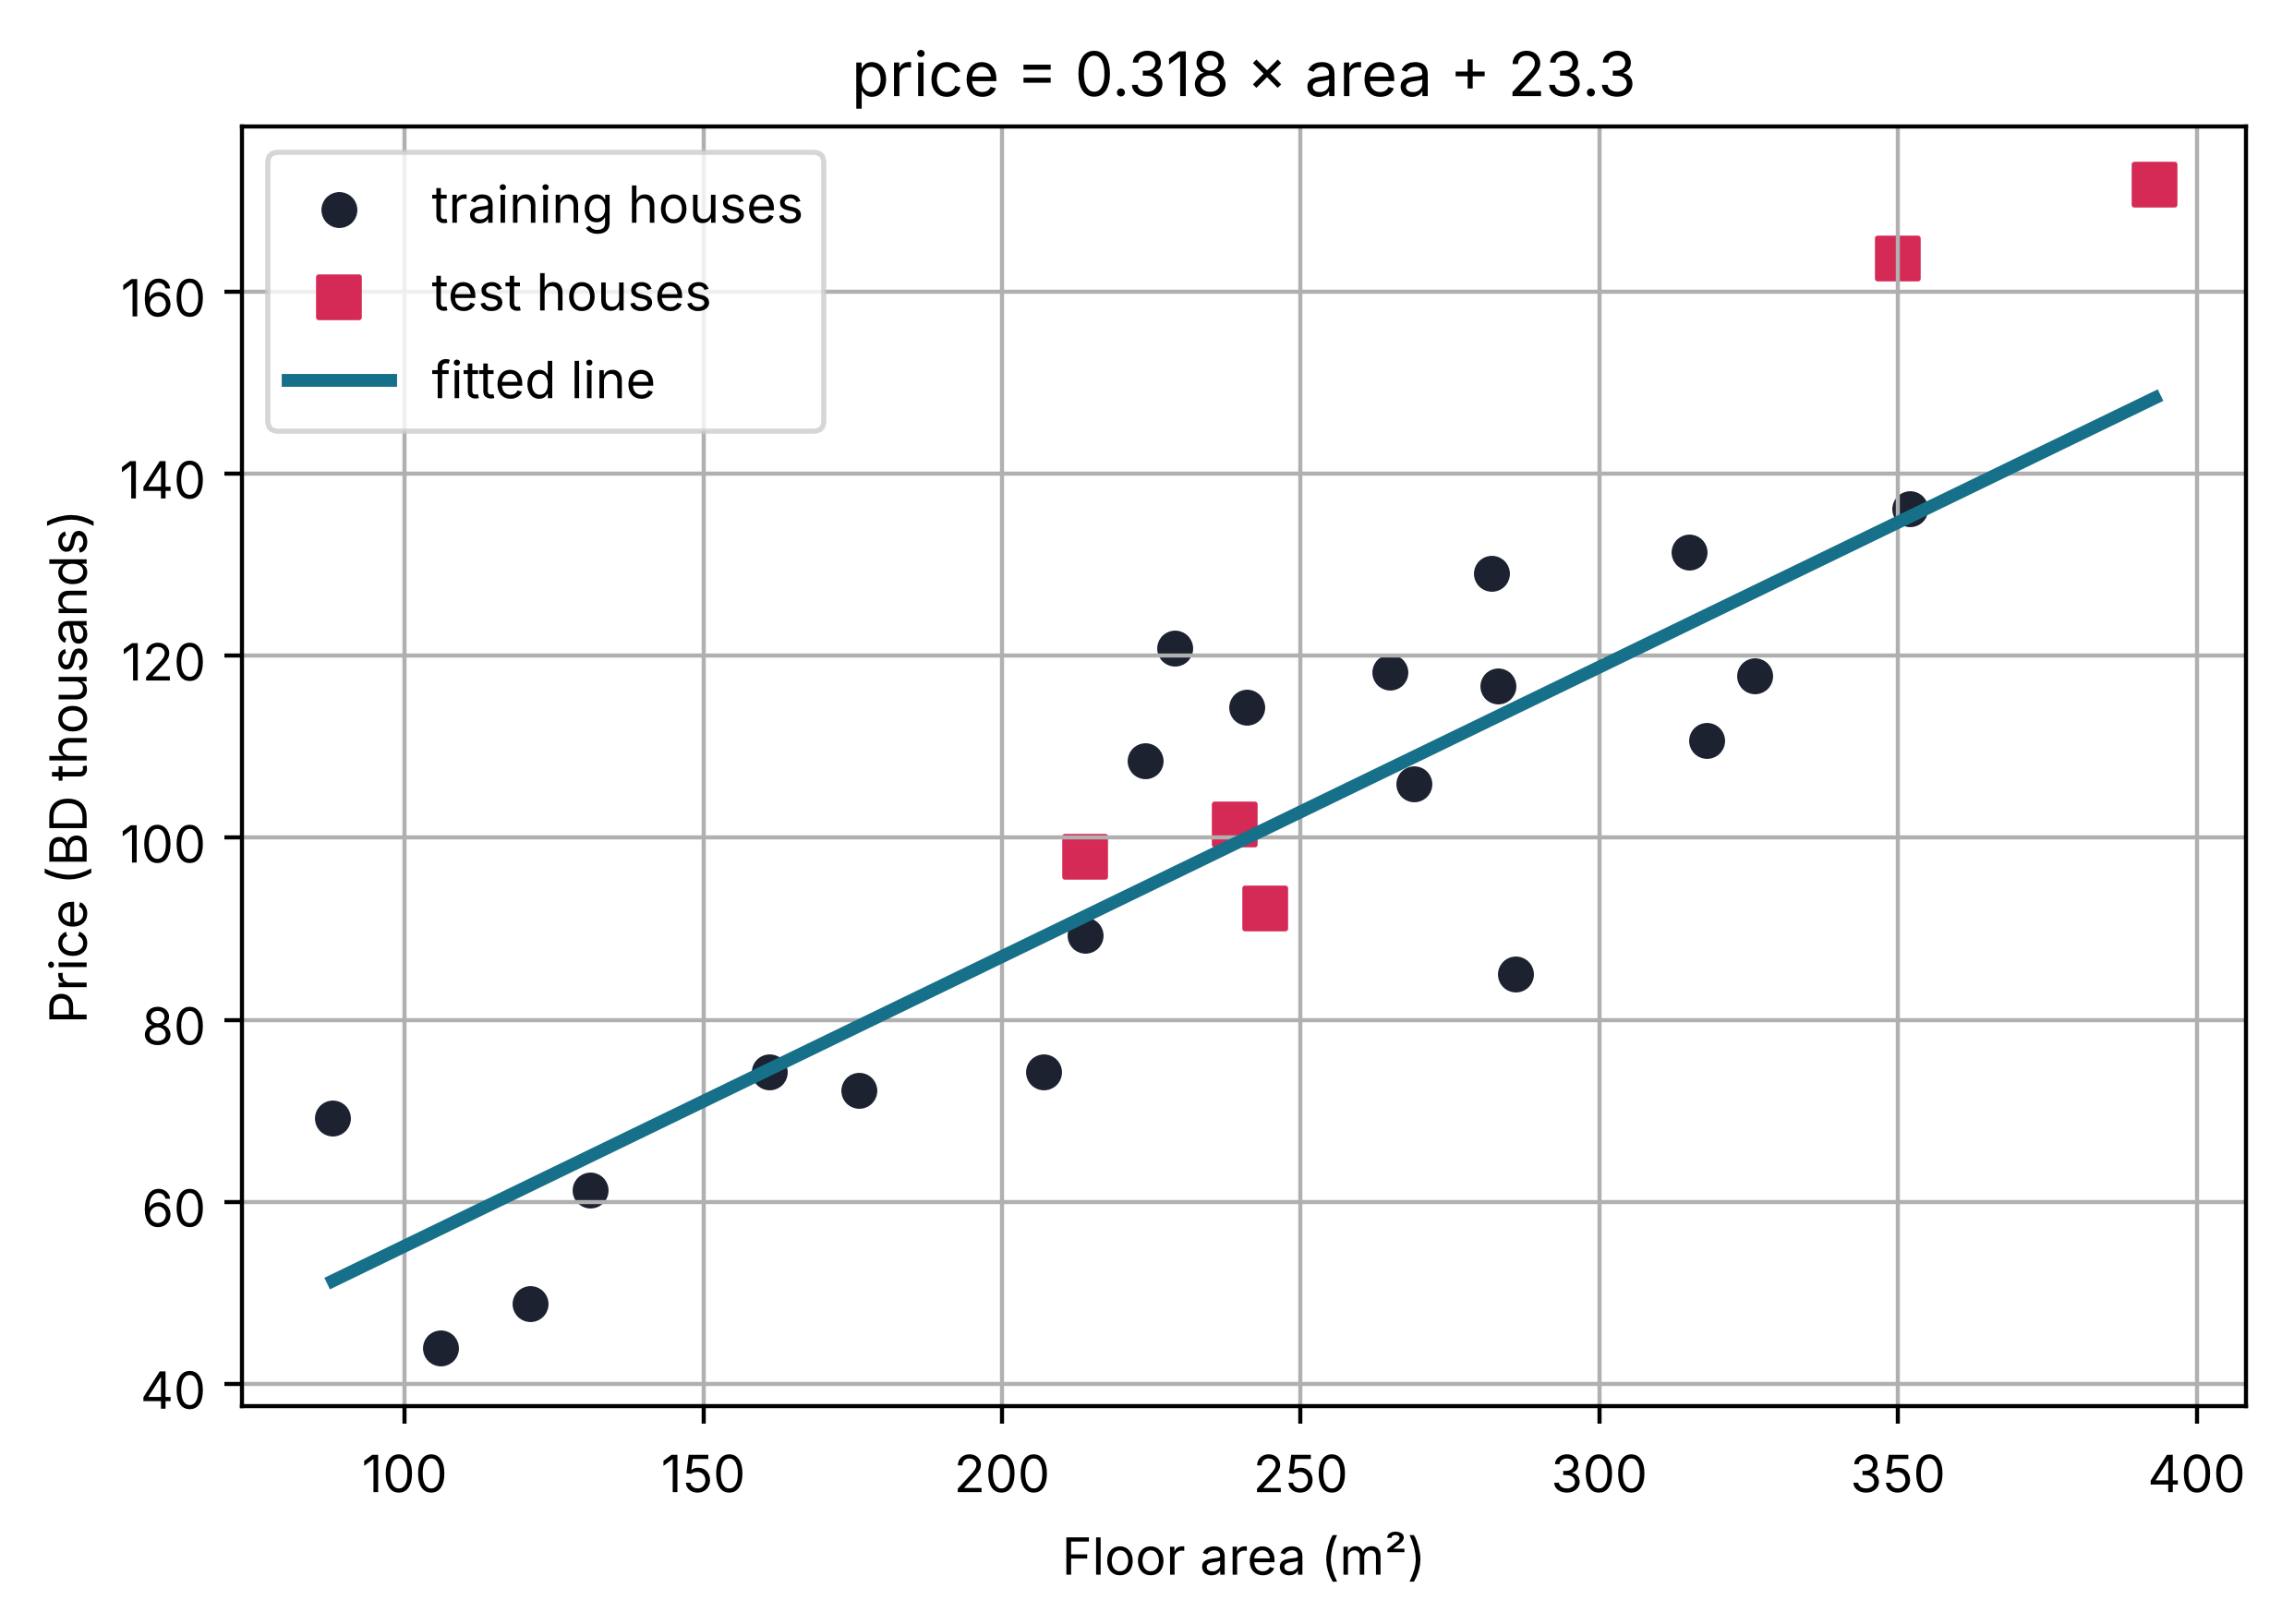

In [11]:
line_x = np.linspace(df["area"].min(), df["area"].max(), 100)
line_y = model.predict(pd.DataFrame({"area": line_x}))

plt.scatter(X_train["area"], y_train, color="#1c2230", label="training houses")
plt.scatter(X_test["area"], y_test, color="#d52a55", marker="s", s=60, label="test houses")
plt.plot(line_x, line_y, color="#17708a", linewidth=2.5, label="fitted line")
plt.xlabel("Floor area (m²)")
plt.ylabel("Price (BD thousands)")
plt.title(f"price = {m:.3f} × area + {b:.1f}")
plt.legend()
plt.show()

**Line by line**

1. `line_x = np.linspace(df["area"].min(), df["area"].max(), 100)`  
   100 evenly spaced areas across the data range, to draw a smooth line.
2. `line_y = model.predict(pd.DataFrame({"area": line_x}))`  
   The predicted price at each of those areas. A DataFrame keeps the column name the model was trained with.
3. `plt.scatter(X_train["area"], y_train, color="#1c2230", label="training houses")`  
   Training houses as dark dots.
4. `plt.scatter(X_test["area"], y_test, color="#d52a55", marker="s", s=60, label="test houses")`  
   Test houses as larger red squares (`s` sets the marker size).
5. `plt.plot(line_x, line_y, color="#17708a", linewidth=2.5, label="fitted line")`  
   The regression line.
6. `plt.xlabel("Floor area (m²)")` …  
   Axis labels and a title.
7. `plt.legend()`  
   Show the key that explains each colour.
8. `plt.show()`  
   Display the chart.

## 9. Diagnose the model with residual plots

A good linear model leaves residuals that look like **random noise**: no curve, no funnel shape, centred on zero.
A clear pattern means the model is missing something (for example, a curve; see the polynomial lesson).

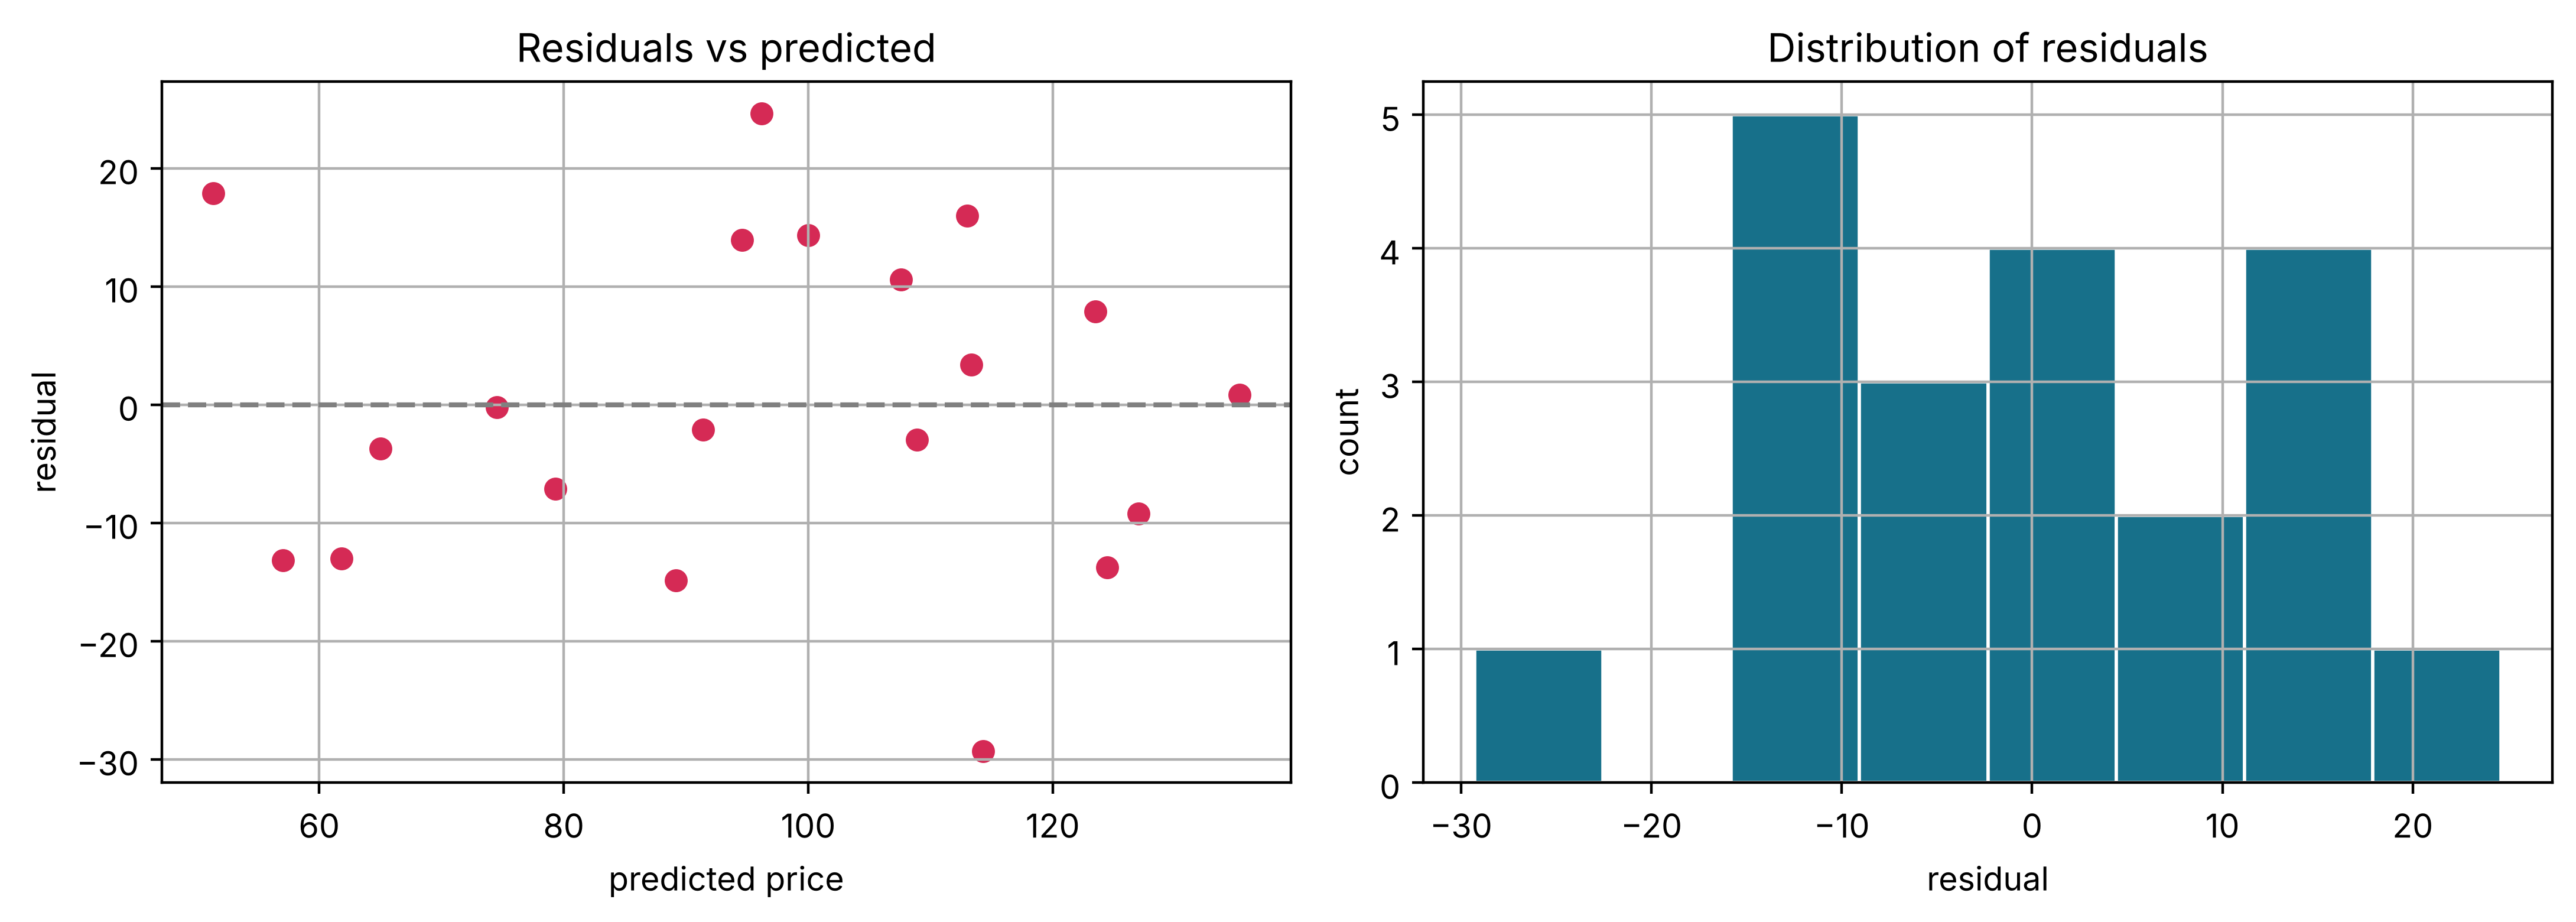

In [12]:
train_pred = model.predict(X_train)
residuals = y_train - train_pred

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(train_pred, residuals, color="#d52a55")
axes[0].axhline(0, color="grey", linestyle="--")
axes[0].set(title="Residuals vs predicted", xlabel="predicted price", ylabel="residual")
axes[1].hist(residuals, bins=8, color="#17708a", edgecolor="white")
axes[1].set(title="Distribution of residuals", xlabel="residual", ylabel="count")
plt.tight_layout()
plt.show()

**Line by line**

1. `train_pred = model.predict(X_train)`  
   Predictions on the training houses.
2. `residuals = y_train - train_pred`  
   Their residuals (actual − predicted).
3. `fig, axes = plt.subplots(1, 2, figsize=(11, 4))`  
   Two panels side by side.
4. `axes[0].scatter(train_pred, residuals, color="#d52a55")`  
   Left: residual against predicted price. We want a shapeless cloud.
5. `axes[0].axhline(0, color="grey", linestyle="--")`  
   A dashed reference line at zero error.
6. `axes[0].set(title="Residuals vs predicted", xlabel="predicted price", ylabel="residual")`  
   Labels for the left panel.
7. `axes[1].hist(residuals, bins=8, color="#17708a", edgecolor="white")`  
   Right: histogram of the residuals. Roughly symmetric around 0 is good.
8. `axes[1].set(title="Distribution of residuals", xlabel="residual", ylabel="count")`  
   Labels for the right panel.
9. `plt.tight_layout()`  
   Tidy the spacing.
10. `plt.show()`  
   Display the figure.

### Predicted vs actual

If every prediction were perfect, all points would sit on the diagonal line $y = x$.

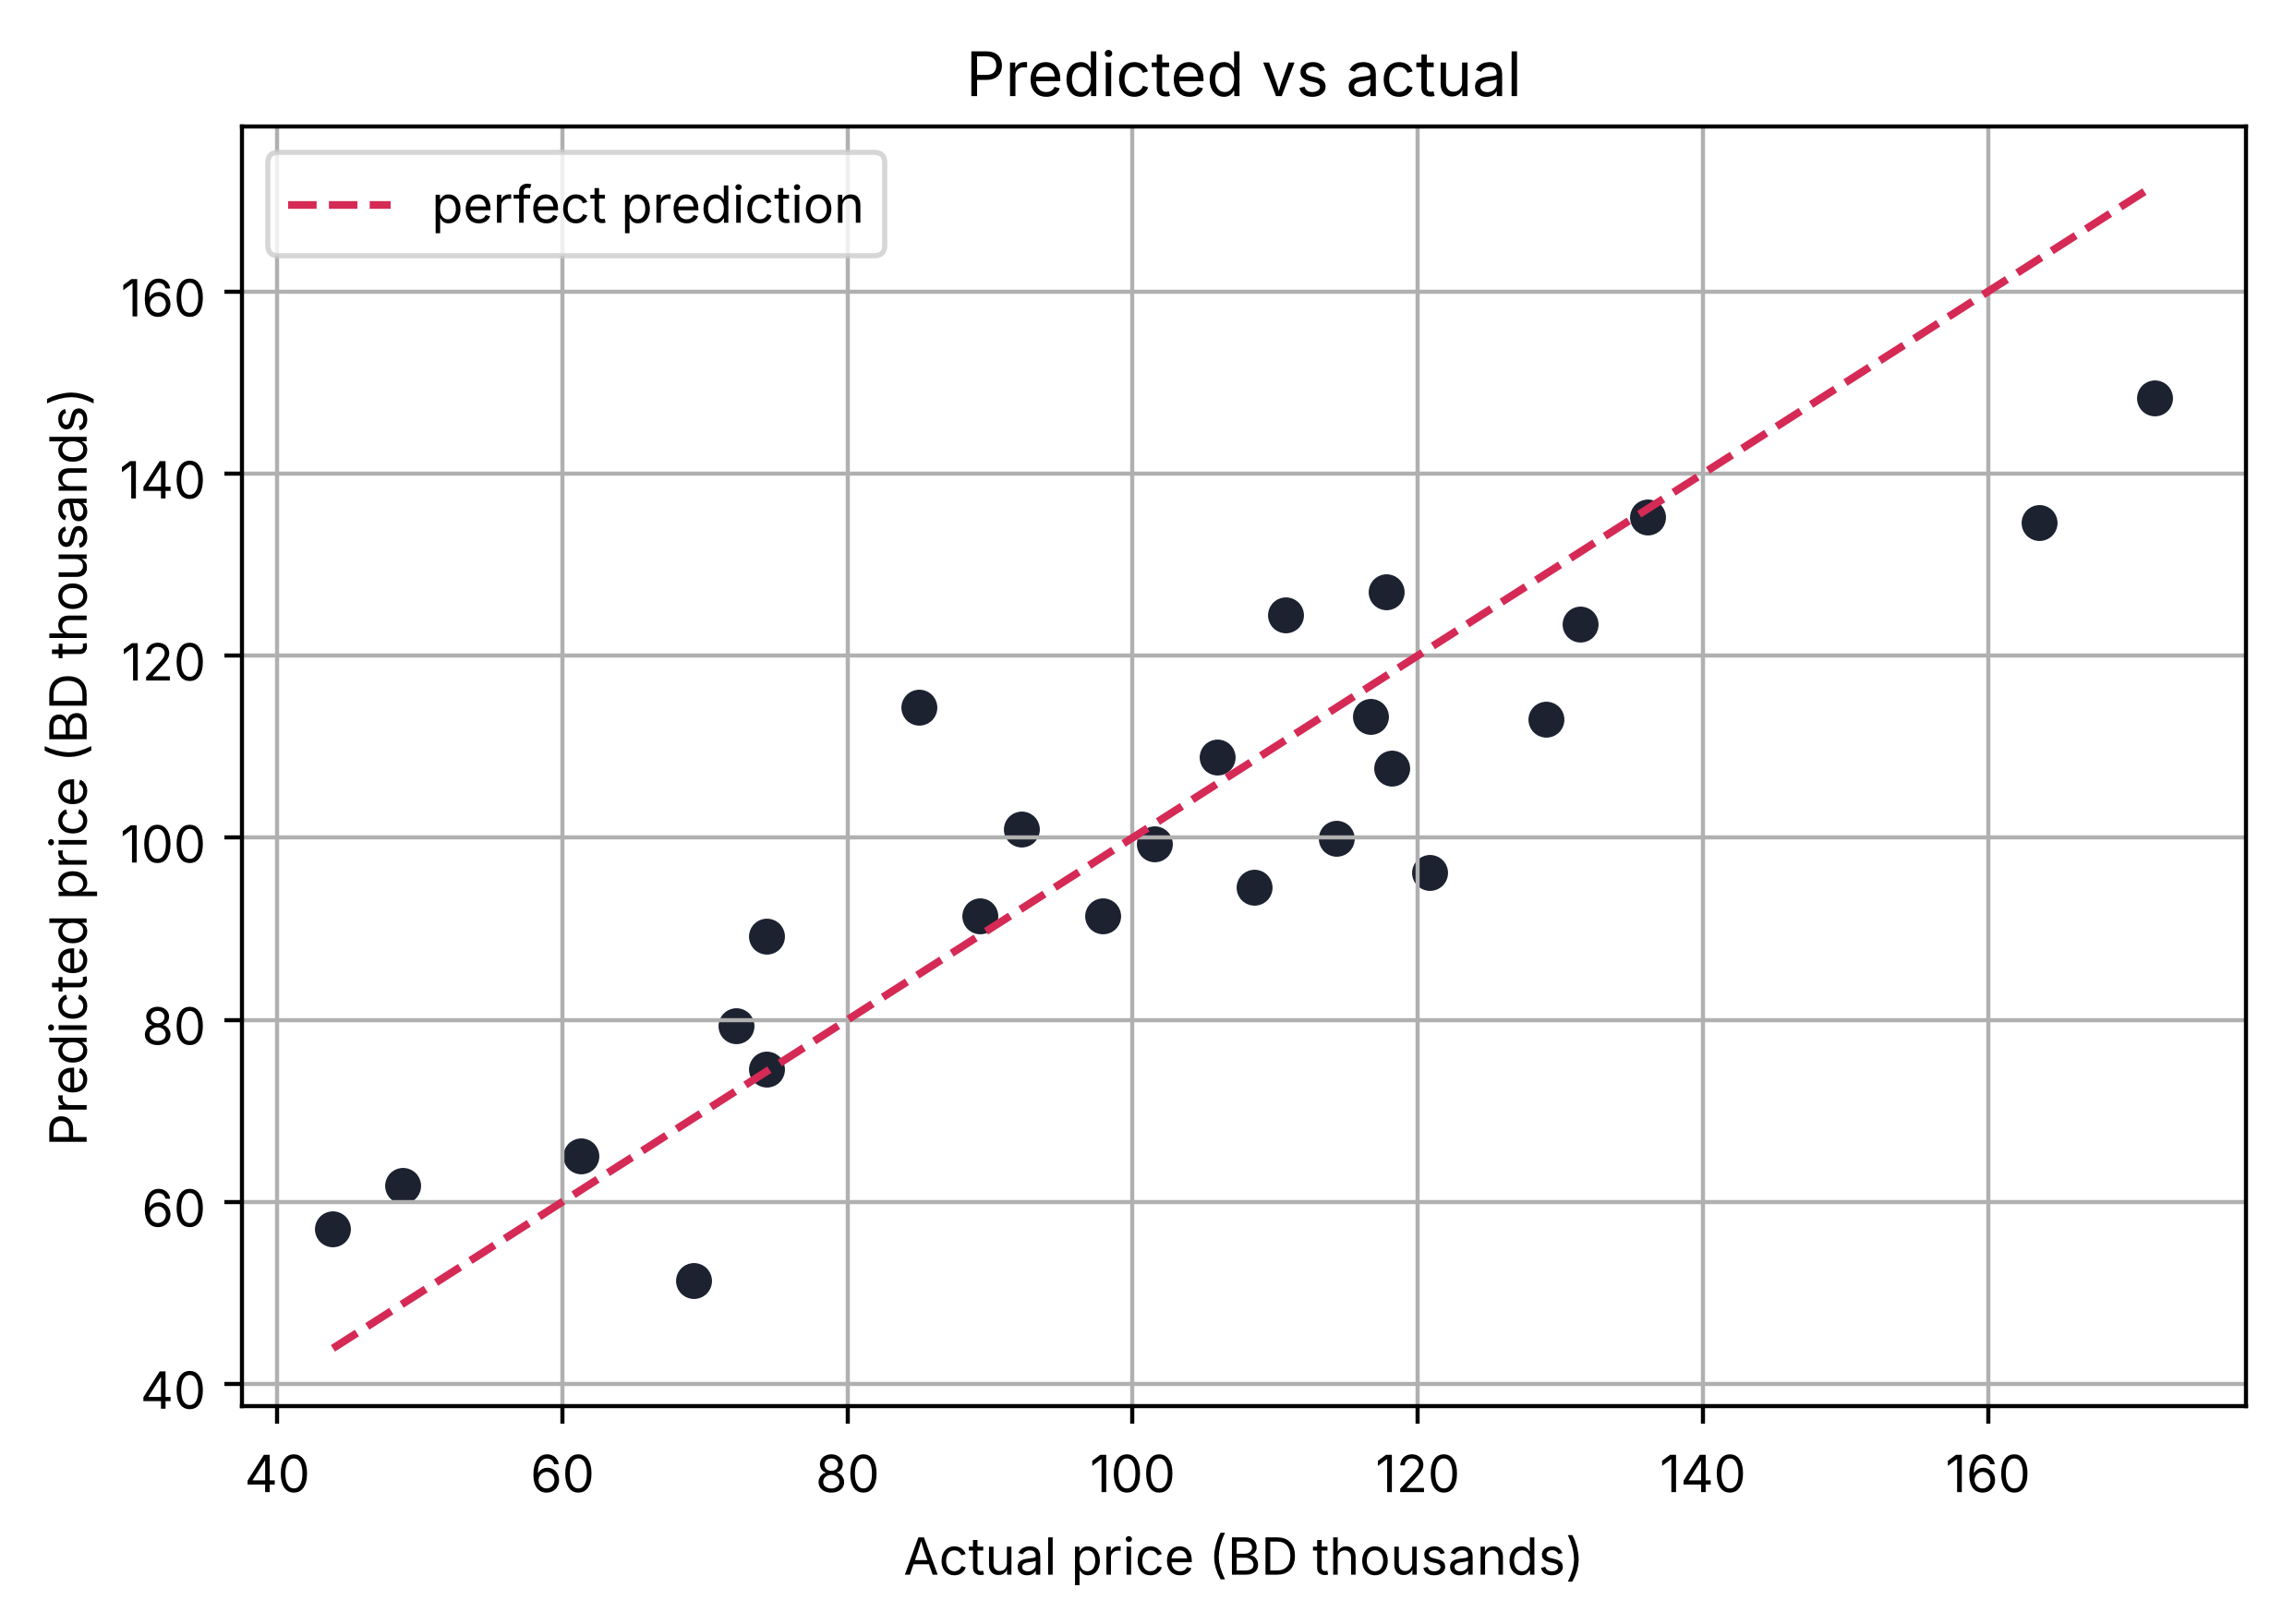

In [13]:
all_pred = model.predict(X)
plt.scatter(y, all_pred, color="#1c2230")
lims = [y.min(), y.max()]
plt.plot(lims, lims, color="#d52a55", linestyle="--", label="perfect prediction")
plt.xlabel("Actual price (BD thousands)")
plt.ylabel("Predicted price (BD thousands)")
plt.title("Predicted vs actual")
plt.legend()
plt.show()

**Line by line**

1. `all_pred = model.predict(X)`  
   Predictions for all 25 houses.
2. `plt.scatter(y, all_pred, color="#1c2230")`  
   Each dot: actual price (across) vs predicted price (up).
3. `lims = [y.min(), y.max()]`  
   The lowest and highest actual prices, used to draw the diagonal.
4. `plt.plot(lims, lims, color="#d52a55", linestyle="--", label="perfect prediction")`  
   The line y = x.
5. `plt.xlabel("Actual price (BD thousands)")` …  
   Labels and title.
6. `plt.legend()`  
   Show the key.
7. `plt.show()`  
   Display the chart.

## 10. Use the model

The trained model can now price houses it has never seen.

In [14]:
new_houses = pd.DataFrame({"area": [120, 250, 380]})
new_houses["predicted_price"] = model.predict(new_houses).round(1)
new_houses

,area,predicted_price
0,120,61.5
1,250,102.8
2,380,144.2


**Line by line**

1. `new_houses = pd.DataFrame({"area": [120, 250, 380]})`  
   Three new houses. The column must have the same name used in training.
2. `new_houses["predicted_price"] = model.predict(new_houses).round(1)`  
   Predict their prices and store them in a new column.
3. `new_houses`  
   Display the result.

> **Careful with extrapolation.** The model learned from houses between roughly 80 and 400 m².
> A prediction for a 2,000 m² palace would be a pure guess: nothing in the data says the straight line continues that far.

## Summary

| Step | Code |
|---|---|
| Load | `pd.read_csv(url)` |
| Split | `train_test_split(X, y, test_size=0.2)` |
| Train | `LinearRegression().fit(X_train, y_train)` |
| Predict | `model.predict(X_test)` |
| Evaluate | `mean_absolute_error`, `mean_squared_error`, `r2_score`, … |
| Diagnose | residual plots, predicted vs actual |

## Exercises

1. Change `random_state=42` to another number and re-run everything. How much do the metrics change? Why?
2. Replace the URL with `.../data/car_age_resale_value.csv` (rename the columns accordingly). Is the slope positive or negative? Interpret it.
3. Add a deliberately wrong row with `df.loc[len(df)] = [150, 300]` right after loading. Which metrics change the most: MAE or RMSE?
4. Try `test_size=0.4`. What happens to the reliability of the test metrics with fewer training houses?